# Convolutional Neural Networks Demo

## Imports, Random Seed and Device Setup

In [52]:
# Basic libraries
import os
import random
import numpy as np
from PIL import Image

# Framework
import torch
import kagglehub
from torchvision import datasets, transforms
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
import torch.nn as nn

# Metrics and analysis
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix
from torchsummary import summary

# Visualization
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from tqdm import tqdm

# Additional libraries
from collections import Counter
import warnings

In [19]:
# Set seed for reproducibility
torch.manual_seed(0)
np.random.seed(0)
random.seed(0)

In [20]:
# Check device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device in Use:", device)

Device in Use: cuda


### Setting up the dataset

In [27]:
# Load the flowers dataset from Kaggle
path = kagglehub.dataset_download("utkarshsaxenadn/flower-classification-5-classes-roselilyetc")

# Dynamically search for the train folder
train_dir = None
val_dir = None
test_dir = None
for root, dirs, files in os.walk(path):
    if 'Training Data' in dirs:
        train_dir = os.path.join(root, 'Training Data')
        val_dir = os.path.join(root, 'Validation Data')
        test_dir = os.path.join(root, 'Testing Data')
        break

for dir_value in [train_dir, val_dir, test_dir]:
  print("\n" + dir_value.split()[-2].split("/")[-1] + " Directory:\n")

  class_names = sorted([d for d in os.listdir(dir_value) if os.path.isdir(os.path.join(dir_value, d))])  # only pick folders and not files
  print(f"Classes found ({len(class_names)}): {class_names}")

  # Pick an image from one of the classes
  sample_class = "Rose"
  sample_class_dir = os.path.join(dir_value, sample_class)
  sample_name = sorted(os.listdir(sample_class_dir))[7]
  print(f"File: {sample_name}")
  sample_image_path = os.path.join(sample_class_dir, sample_name)

  # Open image
  img = Image.open(sample_image_path).convert('RGB')
  img_tensor = transforms.ToTensor()(img)

  # Print the datatype and shape of the image
  print(f"Image Data Type: {img_tensor.dtype}")
  print(f"Image Dimensions (C x H x W): {img_tensor.shape}")

  # Print image counts per class
  print("\nClass Counts:")
  for class_name in class_names:
      class_path = os.path.join(dir_value, class_name)
      count = len([f for f in os.listdir(class_path) if os.path.isfile(os.path.join(class_path, f))])  # only pick files and not folders
      print(f"{class_name} : {count}")


Training Directory:

Classes found (10): ['Aster', 'Daisy', 'Iris', 'Lavender', 'Lily', 'Marigold', 'Orchid', 'Poppy', 'Rose', 'Sunflower']
File: Rose-Train (1004).jpeg
Image Data Type: torch.float32
Image Dimensions (C x H x W): torch.Size([3, 177, 284])

Class Counts:
Aster : 1500
Daisy : 1500
Iris : 1500
Lavender : 1500
Lily : 1500
Marigold : 1500
Orchid : 1500
Poppy : 1500
Rose : 1500
Sunflower : 1500

Validation Directory:

Classes found (10): ['Aster', 'Daisy', 'Iris', 'Lavender', 'Lily', 'Marigold', 'Orchid', 'Poppy', 'Rose', 'Sunflower']
File: Rose-Valid (105).jpeg
Image Data Type: torch.float32
Image Dimensions (C x H x W): torch.Size([3, 275, 183])

Class Counts:
Aster : 500
Daisy : 500
Iris : 500
Lavender : 500
Lily : 500
Marigold : 500
Orchid : 500
Poppy : 500
Rose : 500
Sunflower : 500

Testing Directory:

Classes found (10): ['Aster', 'Daisy', 'Iris', 'Lavender', 'Lily', 'Marigold', 'Orchid', 'Poppy', 'Rose', 'Sunflower']
File: Rose-Test (104).jpeg
Image Data Type: torch

### Visualization of the information present in different channels

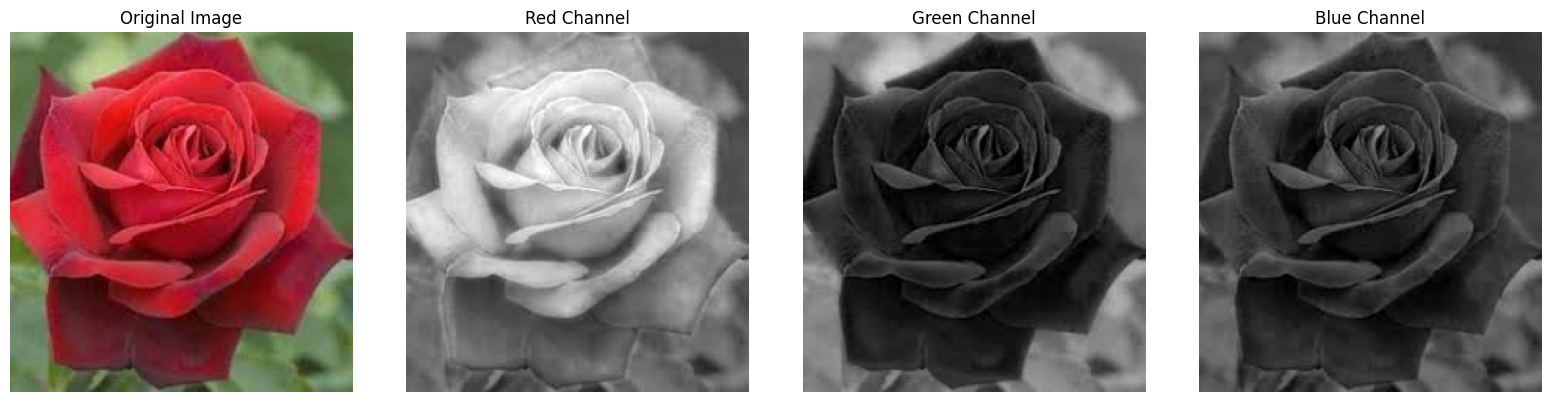

In [30]:
# Pick a sample from the test set
sample_name = "Rose/Rose-Test (104).jpeg"
sample_image_path = os.path.join(test_dir, sample_name)

# Open sample image
img = Image.open(sample_image_path).convert('RGB')
img_tensor = transforms.ToTensor()(img)

# Display the image and its 3 color channels
fig, ax = plt.subplots(1, 4, figsize=(16, 4))

# Show original image
ax[0].imshow(img_tensor.permute(1, 2, 0))
ax[0].set_title("Original Image")
ax[0].axis('off')

# Show individual channels
colors = ['Red', 'Green', 'Blue']

for i in range(3):
    channel_img = torch.zeros_like(img_tensor)
    for j in range(3):
      channel_img[j] = img_tensor[i]
    ax[i+1].imshow(channel_img.permute(1, 2, 0))
    ax[i+1].set_title(f"{colors[i]} Channel")
    ax[i+1].axis('off')

plt.tight_layout()
plt.show()

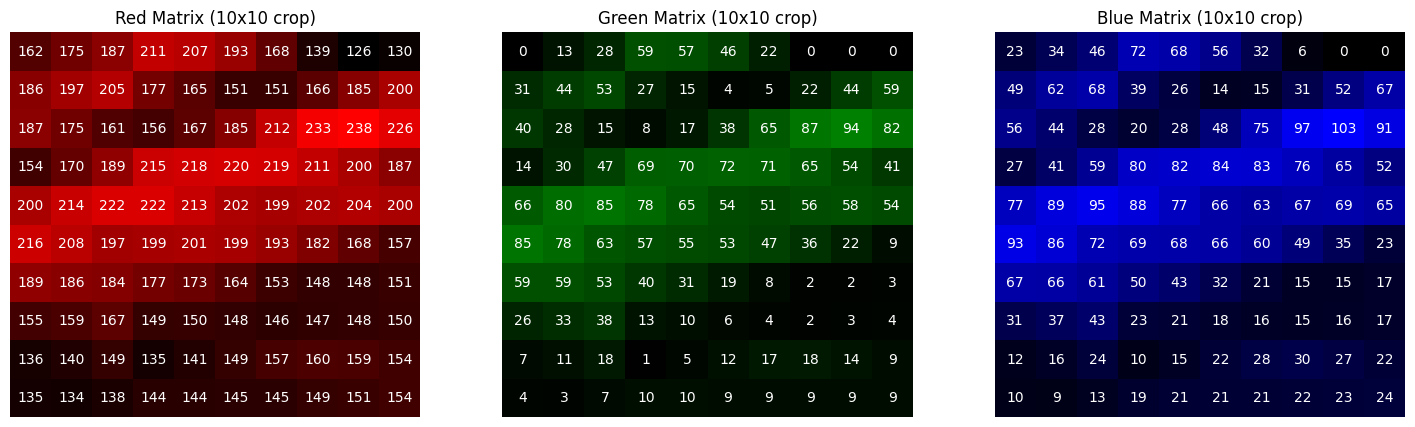

In [ ]:
# Crop a 10x10 region from the image (from the center)
_, h, w = img_tensor.shape
crop = img_tensor[:, h//2 : h//2 + 10, w//2 : w//2 + 10].numpy() * 255
crop = crop.astype(np.uint8)

# Define custom colormaps: Black to Red, Black to Green, Black to Blue
cmap_red = LinearSegmentedColormap.from_list("black_red", ["black", "red"])
cmap_green = LinearSegmentedColormap.from_list("black_green", ["black", "green"])
cmap_blue = LinearSegmentedColormap.from_list("black_blue", ["black", "blue"])

# Define channels and colormaps
colors = ['Red', 'Green', 'Blue']
cmaps = [cmap_red, cmap_green, cmap_blue]

# Show the 3 color channels as matrices of integers (small cropped regions as annotated heatmaps)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, color in enumerate(colors):
    sns.heatmap(crop[i], annot=True, fmt="d", cmap=cmaps[i], ax=axes[i], cbar=False)
    axes[i].set_title(f"{color} Matrix (10x10 crop)")
    axes[i].axis('off')
plt.show()

### Feature detection using convolution

Original input size: torch.Size([1, 3, 230, 219])
Output size after color filter (stride=2): torch.Size([1, 1, 114, 109])
Output size after edge filter (stride=1): torch.Size([1, 1, 112, 107])


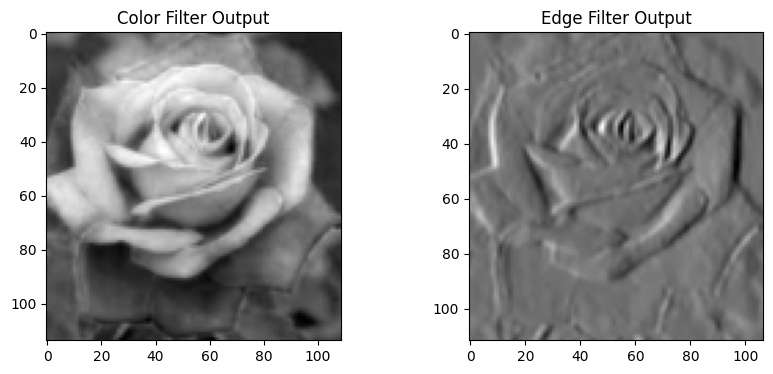

In [36]:
# Prepare image batch [N, C, H, W]
img_batch = img_tensor.unsqueeze(0)

# Design a small color filter (detecting red)
red_filter = torch.tensor([
    [[1., 1., 1.], [1., 1., 1.], [1., 1., 1.]],  # R channel
    [[0., 0., 0.], [0., 0., 0.], [0., 0., 0.]],  # G channel
    [[0., 0., 0.], [0., 0., 0.], [0., 0., 0.]]   # B channel
]).unsqueeze(0) # Shape: [1, 3, 3, 3]

# Apply convolution with stride 2
color_out = F.conv2d(img_batch, red_filter, stride=2, padding=0)

# Design a small edge filter applied to color output
edge_filter = torch.tensor([
    [[-1.,  0.,  1.],
     [-2.,  0.,  2.],
     [-1.,  0.,  1.]]
]).unsqueeze(0) # Shape: [1, 1, 3, 3]

# Apply convolution with stride 1
edge_out = F.conv2d(color_out, edge_filter, stride=1, padding=0)

# Show the sizes of the convolution outputs
print(f"Original input size: {img_batch.shape}")
print(f"Output size after color filter (stride=2): {color_out.shape}")
print(f"Output size after edge filter (stride=1): {edge_out.shape}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(color_out[0, 0].numpy(), cmap='gray')
axes[0].set_title("Color Filter Output")
axes[1].imshow(edge_out[0, 0].numpy(), cmap='gray')
axes[1].set_title("Edge Filter Output")
plt.show()

### Efffect of permutations and maxpooling

Dimension of feature map obtained after pooling: torch.Size([1, 1, 56, 53])
Absolute difference between pooled original and pooled permuted features: 0.0


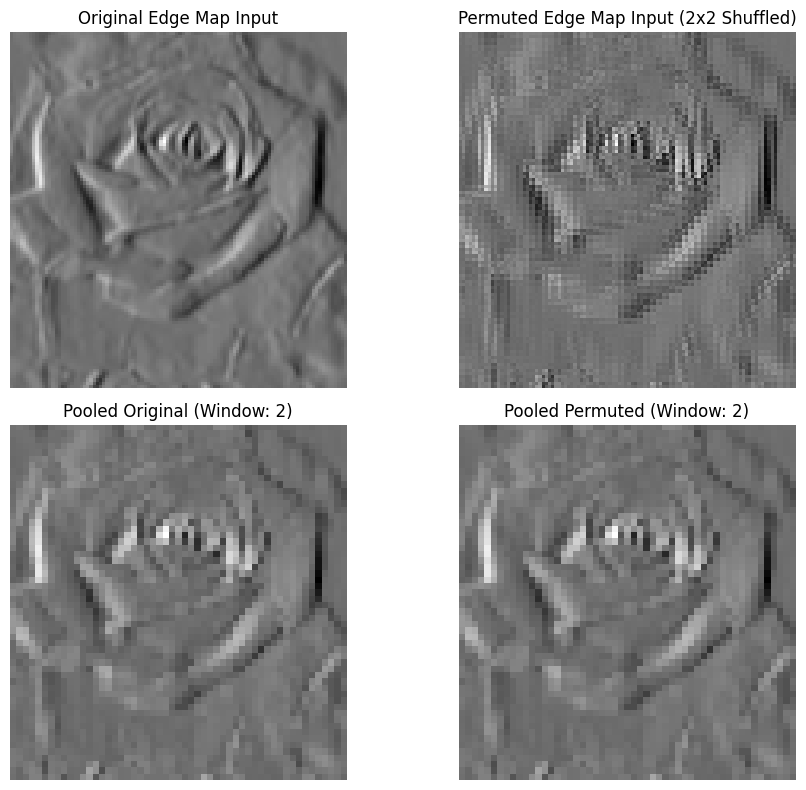

In [37]:
B, C, H, W = edge_out.shape

# Force dimensions to be even by cropping any odd edges
if H % 2 != 0 or W % 2 != 0:
    H = H - (H % 2)
    W = W - (W % 2)
    edge_out = edge_out[:, :, :H, :W]

# Reshape the tensor to group pixels into 2x2 blocks
blocks = edge_out.view(B, C, H // 2, 2, W // 2, 2)

# Reorder dimensions so the 2x2 spatial blocks sit at the end: (B, C, H/2, W/2, 2, 2)
blocks = blocks.permute(0, 1, 2, 4, 3, 5).contiguous()

# Flatten the 2x2 blocks into 1D vectors of length 4
blocks = blocks.view(B, C, H // 2, W // 2, 4)

# Define a permutation (shuffling the 4 pixels within every block). Indices [0, 1, 2, 3] correspond to [top-left, top-right, bottom-left, bottom-right]
shuffle_idx = torch.tensor([3, 2, 1, 0])
permuted_blocks = blocks[:, :, :, :, shuffle_idx]

# Reconstruct the permuted edge map back to the original (B, C, H, W) shape
permuted_blocks = permuted_blocks.view(B, C, H // 2, W // 2, 2, 2)
permuted_blocks = permuted_blocks.permute(0, 1, 2, 4, 3, 5).contiguous()
edge_out_permuted = permuted_blocks.view(B, C, H, W)

# Perform pooling
pool_window = 2
pooled_original = F.max_pool2d(edge_out, kernel_size=pool_window, stride=pool_window)
pooled_permuted = F.max_pool2d(edge_out_permuted, kernel_size=pool_window, stride=pool_window)

print(f"Dimension of feature map obtained after pooling: {pooled_original.shape}")

# Verify identical results
diff = torch.abs(pooled_original - pooled_permuted).sum().item()
print(f"Absolute difference between pooled original and pooled permuted features: {diff}")

# Plotting inputs (Row 1) and outputs (Row 2)
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

# Pre-pooling Edge Maps
axes[0, 0].imshow(edge_out[0, 0].detach().numpy(), cmap='gray')
axes[0, 0].set_title("Original Edge Map Input")
axes[0, 0].axis('off')

axes[0, 1].imshow(edge_out_permuted[0, 0].detach().numpy(), cmap='gray')
axes[0, 1].set_title("Permuted Edge Map Input (2x2 Shuffled)")
axes[0, 1].axis('off')

# Post-pooling Outputs
axes[1, 0].imshow(pooled_original[0, 0].detach().numpy(), cmap='gray')
axes[1, 0].set_title(f"Pooled Original (Window: {pool_window})")
axes[1, 0].axis('off')

axes[1, 1].imshow(pooled_permuted[0, 0].detach().numpy(), cmap='gray')
axes[1, 1].set_title(f"Pooled Permuted (Window: {pool_window})")
axes[1, 1].axis('off')

plt.tight_layout()
plt.show()

### Data preparation

In [40]:
batch_size = 16
img_size = 64

# Create a custom ImageFolder that filters for specific classes
class FilteredImageFolder(datasets.ImageFolder):
    def __init__(self, root, target_classes, transform=None):
        self.target_classes = set(target_classes)
        super().__init__(root, transform=transform)

    def find_classes(self, directory):
        # Get all classes from the default ImageFolder implementation
        classes, _ = super().find_classes(directory)

        # Keep only the target classes, sorted alphabetically
        filtered_classes = sorted([c for c in classes if c in self.target_classes])

        # Re-map the class indices to 0, 1, 2, 3, 4
        class_to_idx = {c: i for i, c in enumerate(filtered_classes)}

        return filtered_classes, class_to_idx

# Define the desired classes
target_classes = ['Sunflower', 'Rose', 'Lavender', 'Aster', 'Marigold']

# Transforms for training and evaluation
train_transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=30),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.01),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

eval_transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

# Apply transforms for selected classes
train_data = FilteredImageFolder(train_dir, target_classes=target_classes, transform=train_transform)
val_data = FilteredImageFolder(val_dir, target_classes=target_classes, transform=eval_transform)
test_data = FilteredImageFolder(test_dir, target_classes=target_classes, transform=eval_transform)

# Create DataLoaders
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_data, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_data, batch_size=1, shuffle=False)

# Print out the final dataset for the task
classes = train_data.classes
print(f"Classes: {classes}")
print(f"Training samples: {len(train_data)} | Validation samples: {len(val_data)} | Testing samples: {len(test_data)}")

Classes: ['Aster', 'Lavender', 'Marigold', 'Rose', 'Sunflower']
Training samples: 7500 | Validation samples: 2500 | Testing samples: 1068


In [43]:
# Helper function to safely extract targets through nested Subsets
def get_subset_targets(dataset):
    if hasattr(dataset, 'dataset') and hasattr(dataset, 'indices'):
        parent_targets = get_subset_targets(dataset.dataset)
        return [parent_targets[i] for i in dataset.indices]
    elif hasattr(dataset, 'targets'):
        return dataset.targets
    else:
        raise ValueError("Dataset does not have 'targets' or 'indices'")

# Helper function to print the distribution
def print_class_distribution(subset, split_name, class_names):
    targets = get_subset_targets(subset)
    counts = Counter(targets)

    print(f"\n{split_name} Distribution:")
    for class_idx in sorted(counts.keys()):
        print(f"  - {class_names[class_idx]}: {counts[class_idx]} samples")
    print(f"  Total: {len(targets)} samples")

# Print the distribution of final dataset
classes = train_data.classes
print(f"Classes available: {classes}")

print_class_distribution(train_data, "Train", classes)
print_class_distribution(val_data, "Validation", classes)
print_class_distribution(test_data, "Test", classes)

Classes available: ['Aster', 'Lavender', 'Marigold', 'Rose', 'Sunflower']

Train Distribution:
  - Aster: 1500 samples
  - Lavender: 1500 samples
  - Marigold: 1500 samples
  - Rose: 1500 samples
  - Sunflower: 1500 samples
  Total: 7500 samples

Validation Distribution:
  - Aster: 500 samples
  - Lavender: 500 samples
  - Marigold: 500 samples
  - Rose: 500 samples
  - Sunflower: 500 samples
  Total: 2500 samples

Test Distribution:
  - Aster: 146 samples
  - Lavender: 217 samples
  - Marigold: 108 samples
  - Rose: 269 samples
  - Sunflower: 328 samples
  Total: 1068 samples


### Architecture of the model

In [46]:
# Design a CNN with few convolution and pooling layers followed by fully connected layers
class ClassifierCNN(nn.Module):
    def __init__(self, num_classes):
        super(ClassifierCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 8 * 8, 1024),
            nn.ReLU(),
            nn.Dropout(p=0.5),
            nn.Linear(1024, 1024),
            nn.ReLU(),
            nn.Dropout(p=0.5),
            nn.Linear(1024, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

model = ClassifierCNN(num_classes=len(classes)).to(device)

# Show the summary of the model architecture and the number of trainable parameters
summary(model, (3, img_size, img_size))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 32, 64, 64]             896
       BatchNorm2d-2           [-1, 32, 64, 64]              64
              ReLU-3           [-1, 32, 64, 64]               0
            Conv2d-4           [-1, 32, 64, 64]           9,248
       BatchNorm2d-5           [-1, 32, 64, 64]              64
              ReLU-6           [-1, 32, 64, 64]               0
         MaxPool2d-7           [-1, 32, 32, 32]               0
            Conv2d-8           [-1, 64, 32, 32]          18,496
       BatchNorm2d-9           [-1, 64, 32, 32]             128
             ReLU-10           [-1, 64, 32, 32]               0
           Conv2d-11           [-1, 64, 32, 32]          36,928
      BatchNorm2d-12           [-1, 64, 32, 32]             128
             ReLU-13           [-1, 64, 32, 32]               0
        MaxPool2d-14           [-1, 64,

### Loss function and optimizer

In [50]:
# Define the categorical cross entropy loss
criterion = nn.CrossEntropyLoss()

# Initialize the optimizer
optimizer = optim.Adam(model.parameters(), lr=1e-3)

### Training and validation

Epoch 1/50 [Valid]: 100%|██████████| 157/157 [00:03<00:00, 43.28it/s]


--> Train Loss: 1.2580 | Val Loss: 0.8911


Epoch 2/50 [Valid]: 100%|██████████| 157/157 [00:03<00:00, 43.73it/s]


--> Train Loss: 1.0404 | Val Loss: 0.6995


Epoch 3/50 [Valid]: 100%|██████████| 157/157 [00:04<00:00, 38.26it/s]


--> Train Loss: 0.9596 | Val Loss: 0.7275


... (90 outputs left out)

Epoch 49/50 [Valid]: 100%|██████████| 157/157 [00:03<00:00, 43.72it/s]


--> Train Loss: 0.3532 | Val Loss: 0.3175


Epoch 50/50 [Valid]: 100%|██████████| 157/157 [00:03<00:00, 43.83it/s]


--> Train Loss: 0.3663 | Val Loss: 0.2728


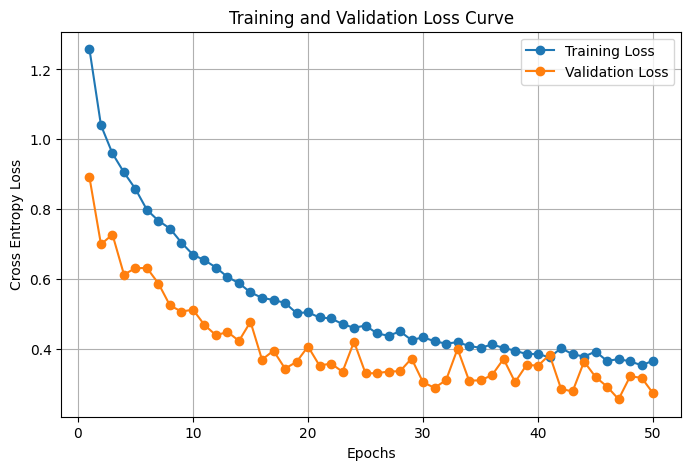

In [53]:
# Train the CNN for a suitable number of epochs
num_epochs = 50
train_losses, val_losses = [], []

for epoch in range(num_epochs):
    # Train
    model.train()
    running_loss = 0.0
    for images, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Train]"):
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    epoch_train_loss = running_loss / len(train_loader.dataset)
    train_losses.append(epoch_train_loss)

    # Validate
    model.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Valid]"):
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            running_val_loss += loss.item() * images.size(0)

    epoch_val_loss = running_val_loss / len(val_loader.dataset)
    val_losses.append(epoch_val_loss)

    print(f"--> Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f}")

# Plot the training and validation losses
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), train_losses, label='Training Loss', marker='o')
plt.plot(range(1, num_epochs + 1), val_losses, label='Validation Loss', marker='o')
plt.xlabel('Epochs')
plt.ylabel('Cross Entropy Loss')
plt.title('Training and Validation Loss Curve')
plt.legend()
plt.grid(True)
plt.show()

### Predictions on the test samples

Model weights saved to cnn_model.pth


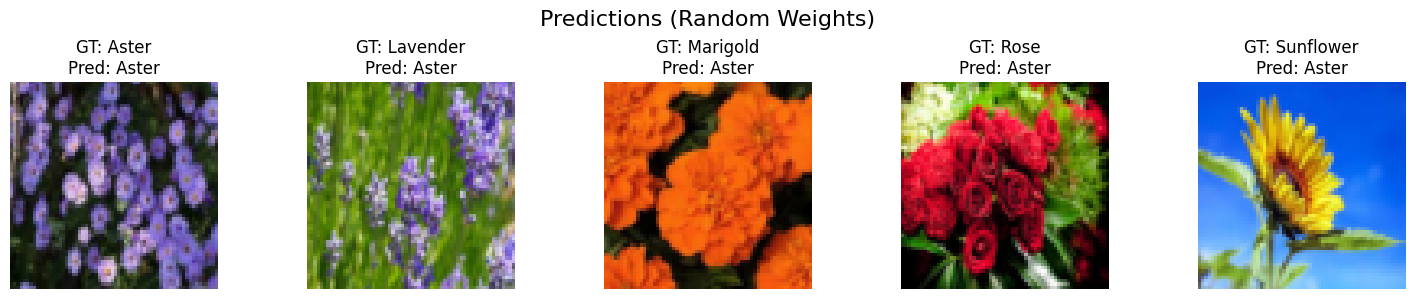

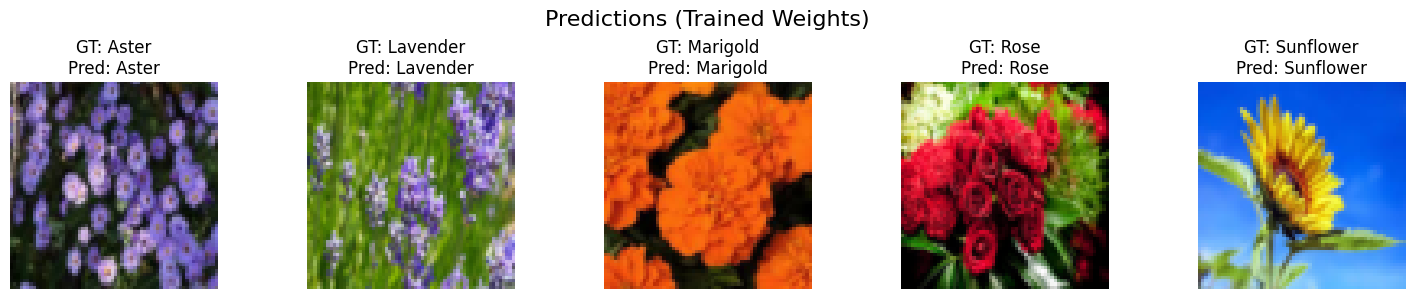

In [54]:
# Save the trained model weights on disk
weights_path = 'cnn_model.pth'
torch.save(model.state_dict(), weights_path)
print(f"Model weights saved to {weights_path}")

random.seed(12345)

needed_classes = set(range(len(classes))) # Tracks which classes we still need
sample_indices = []

# Shuffle indices to ensure we get different random images on each run
all_indices = list(range(len(test_data)))
random.shuffle(all_indices)

# Fetch images one by one until we have one from each class
for idx in all_indices:
    _, label = test_data[idx]

    if label in needed_classes:
        sample_indices.append(idx)
        needed_classes.remove(label)

    # Stop searching once we have all classes to save time
    if not needed_classes:
        break

# Sort the indices so that the plot always displays classes in order (0 to 4)
sample_indices.sort(key=lambda x: test_data[x][1])

# Helper function to plot predictions
def plot_predictions(predictive_model, title_suffix):
    predictive_model.eval()
    fig, axes = plt.subplots(1, 5, figsize=(15, 3))

    for i, idx in enumerate(sample_indices):
        img, label = test_data[idx]
        img_input = img.unsqueeze(0).to(device)

        with torch.no_grad():
            output = predictive_model(img_input)
            pred = output.argmax(dim=1).item()

        # Denormalize image for display
        img_display = img.permute(1, 2, 0).numpy()
        img_display = img_display * 0.5 + 0.5

        axes[i].imshow(np.clip(img_display, 0, 1))
        axes[i].set_title(f"GT: {classes[label]}\nPred: {classes[pred]}")
        axes[i].axis('off')

    fig.suptitle(f"Predictions {title_suffix}", fontsize=16)
    plt.tight_layout()
    plt.show()

# Re-initialize the model (random weights) and predict
untrained_model = ClassifierCNN(num_classes=len(classes)).to(device)
plot_predictions(untrained_model, "(Random Weights)")

# Load the learned weights and repeat the predictions
loaded_model = ClassifierCNN(num_classes=len(classes)).to(device)
loaded_model.load_state_dict(torch.load(weights_path))
plot_predictions(loaded_model, "(Trained Weights)")

Evaluating on Test Set: 100%|██████████| 1068/1068 [00:02<00:00, 377.82it/s]



--- Test Set Metrics ---
Accuracy:  91.95%
Precision: 92.32%
Recall:    91.95%


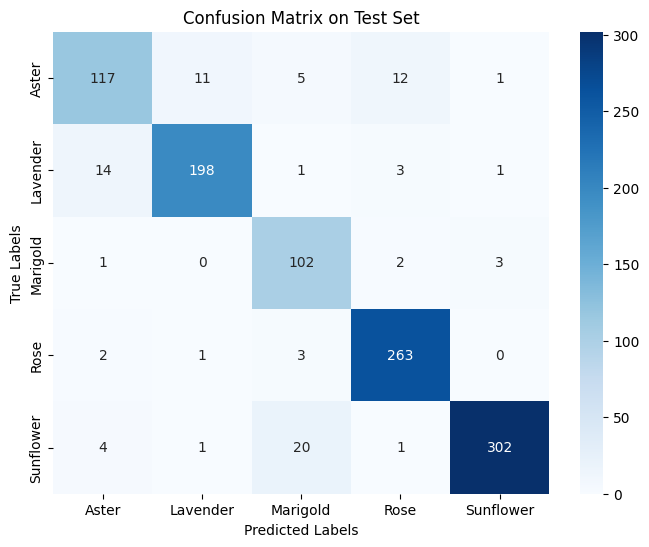

In [55]:
# Report accuracy, precision, recall, and show the confusion matrix on the test set.
all_preds = []
all_labels = []

loaded_model.eval()
with torch.no_grad():
    for images, labels in tqdm(test_loader, desc="Evaluating on Test Set"):
        images = images.to(device)
        outputs = loaded_model(images)
        preds = outputs.argmax(dim=1).cpu().numpy()

        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

# Calculate metrics
acc = accuracy_score(all_labels, all_preds)
prec = precision_score(all_labels, all_preds, average='weighted', zero_division=0)
rec = recall_score(all_labels, all_preds, average='weighted', zero_division=0)

print(f"\n--- Test Set Metrics ---")
print(f"Accuracy:  {acc * 100:.2f}%")
print(f"Precision: {prec * 100:.2f}%")
print(f"Recall:    {rec * 100:.2f}%")

# Plot Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=classes, yticklabels=classes)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix on Test Set')
plt.show()